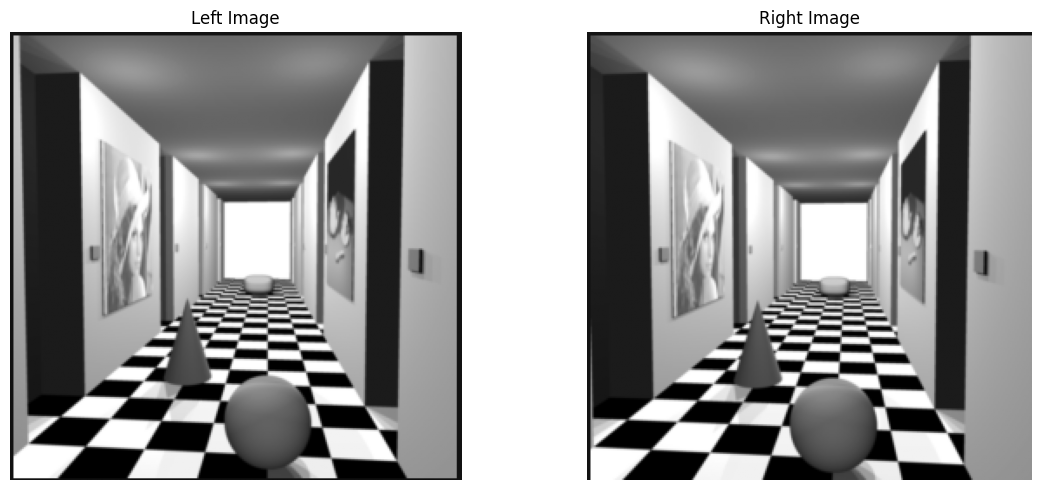

Left image shape: (259, 261)
Right image shape: (257, 255)


In [ ]:
#activity 1
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the left and right images in grayscale (corrected extensions to .png)
img_left = cv2.imread('/content/cv3.png', 0)
img_right = cv2.imread('/content/cv4.png', 0)

# Check whether the images were loaded
if img_left is None or img_right is None:
    print("Error: Could not load the images. Check the file paths.")
else:
    # Display both images
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img_left, cmap='gray')
    plt.title("Left Image")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_right, cmap='gray')
    plt.title("Right Image")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    print("Left image shape:", img_left.shape)
    print("Right image shape:", img_right.shape)

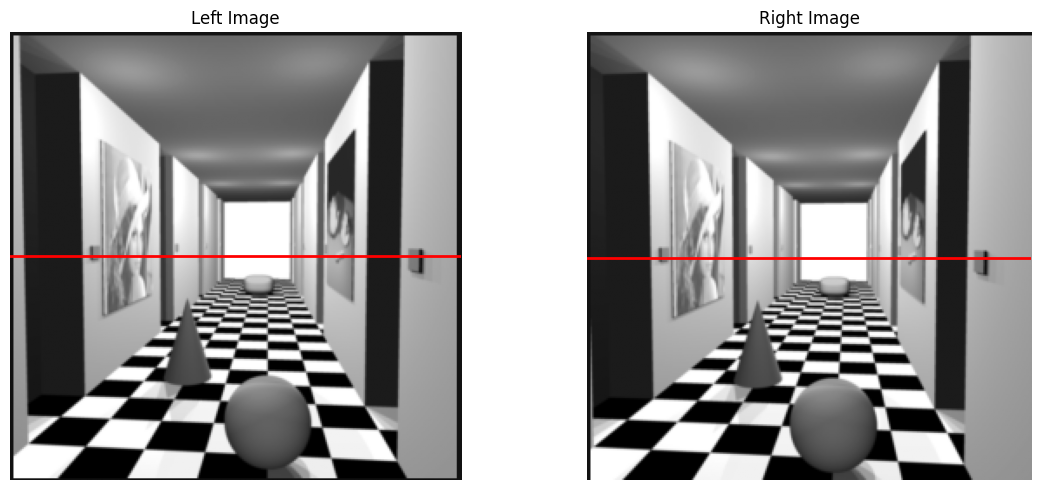

In [ ]:
#activity 2:
# Find the middle row of the left image
row = img_left.shape[0] // 2

# Display both images with a horizontal line
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_left, cmap='gray')
plt.axhline(row, color='red', linewidth=2)
plt.title("Left Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_right, cmap='gray')
plt.axhline(row, color='red', linewidth=2)
plt.title("Right Image")
plt.axis('off')

plt.tight_layout()
plt.show()

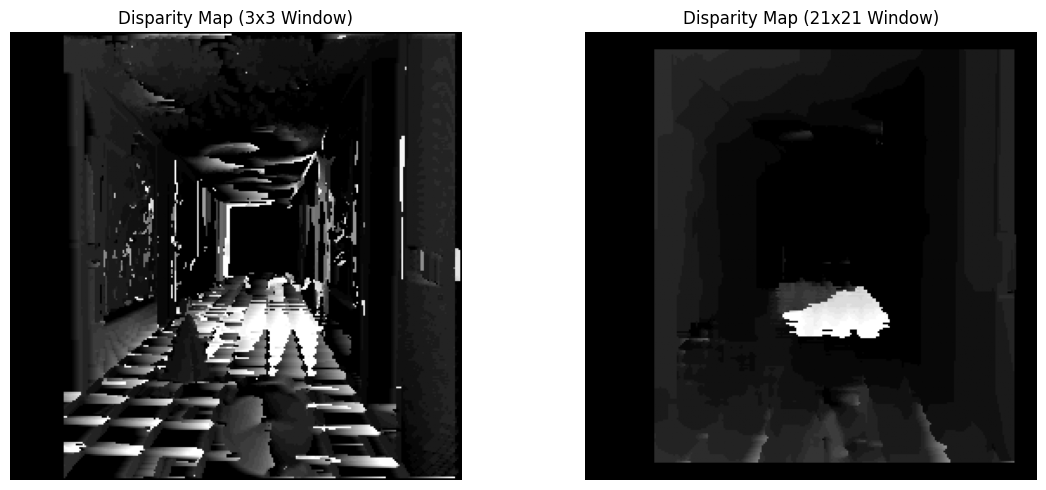

In [ ]:
#activity 3
def compute_ssd_disparity(left_img, right_img, window_size, max_disparity=30):
    # Ensure both images have the same dimensions by resizing the right image to match the left
    if left_img.shape != right_img.shape:
        right_img = cv2.resize(right_img, (left_img.shape[1], left_img.shape[0]))

    h, w = left_img.shape
    half = window_size // 2

    disparity_map = np.zeros((h, w), dtype=np.float32)

    left_img = left_img.astype(np.float32)
    right_img = right_img.astype(np.float32)

    for y in range(half, h - half):
        for x in range(half + max_disparity, w - half):

            left_patch = left_img[
                y-half:y+half+1,
                x-half:x+half+1
            ]

            min_ssd = float('inf')
            best_disparity = 0

            for disparity in range(max_disparity):
                x_right = x - disparity

                if x_right - half < 0:
                    break

                right_patch = right_img[
                    y-half:y+half+1,
                    x_right-half:x_right+half+1
                ]

                # Now both patches are guaranteed to be the same shape
                ssd = np.sum((left_patch - right_patch) ** 2)

                if ssd < min_ssd:
                    min_ssd = ssd
                    best_disparity = disparity

            disparity_map[y, x] = best_disparity

    return disparity_map


# Calculate disparity using a 3x3 window
disp_3 = compute_ssd_disparity(
    img_left, img_right, window_size=3, max_disparity=30
)

# Calculate disparity using a 21x21 window
disp_21 = compute_ssd_disparity(
    img_left, img_right, window_size=21, max_disparity=30
)

# Display both disparity maps
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(disp_3, cmap='gray')
plt.title("Disparity Map (3x3 Window)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(disp_21, cmap='gray')
plt.title("Disparity Map (21x21 Window)")
plt.axis('off')

plt.tight_layout()
plt.show()

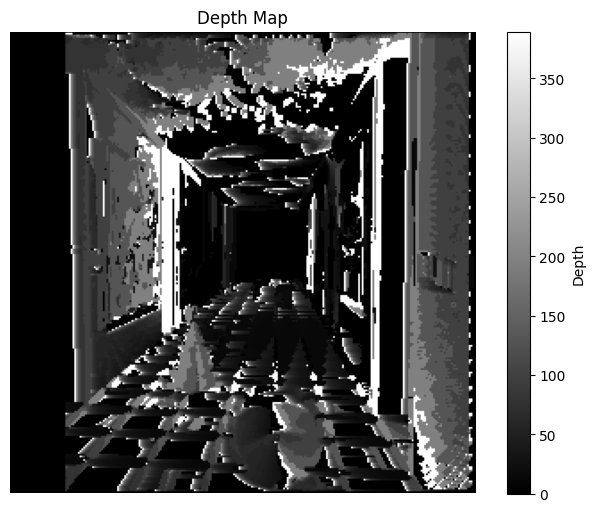

In [ ]:
#activity 4
# Camera parameters
B = 0.54
f = 721.5

def compute_depth(disparity_map, baseline, focal_length):
    depth_map = np.zeros_like(disparity_map, dtype=np.float32)

    # Only calculate depth where disparity is greater than zero
    valid = disparity_map > 0

    depth_map[valid] = (
        baseline * focal_length
    ) / disparity_map[valid]

    return depth_map


# Calculate depth using the 3x3 disparity map
depth_map = compute_depth(disp_3, B, f)

# Display the depth map
plt.figure(figsize=(8, 6))
plt.imshow(depth_map, cmap='gray')
plt.title("Depth Map")
plt.colorbar(label="Depth")
plt.axis('off')
plt.show()

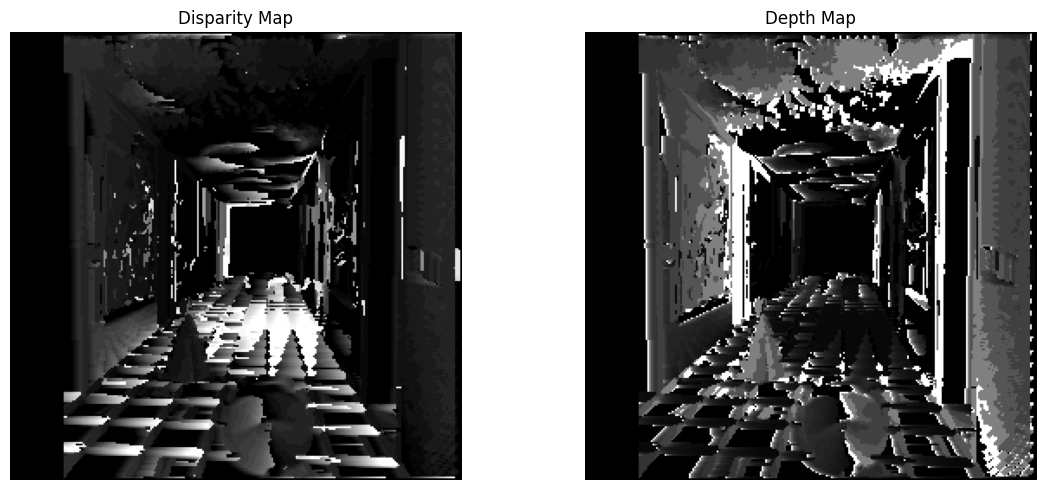

In [ ]:
#activity 5
# Display the disparity and depth maps
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(disp_3, cmap='gray')
plt.title("Disparity Map")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(depth_map, cmap='gray')
plt.title("Depth Map")
plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
#activity 6 a
# Camera parameters
B = 0.54
f = 721.5

# Different disparity values
disparities = [5, 10, 20, 30]

for d in disparities:
    depth = (B * f) / d
    print(f"Disparity: {d}, Depth: {depth:.2f} meters")

Disparity: 5, Depth: 77.92 meters
Disparity: 10, Depth: 38.96 meters
Disparity: 20, Depth: 19.48 meters
Disparity: 30, Depth: 12.99 meters


In [ ]:
#activity 6 b
# Fixed focal length and disparity
f = 721.5
d = 20

# Different baseline values
baselines = [0.30, 0.54, 1.00]

for B in baselines:
    depth = (B * f) / d
    print(f"Baseline: {B}, Depth: {depth:.2f} meters")

Baseline: 0.3, Depth: 10.82 meters
Baseline: 0.54, Depth: 19.48 meters
Baseline: 1.0, Depth: 36.08 meters


In [ ]:
#activity 6c
# Fixed baseline and disparity
B = 0.54
d = 20

# Different focal length values
focal_lengths = [500, 721.5, 1000]

for f in focal_lengths:
    depth = (B * f) / d
    print(f"Focal Length: {f}, Depth: {depth:.2f} meters")

Focal Length: 500, Depth: 13.50 meters
Focal Length: 721.5, Depth: 19.48 meters
Focal Length: 1000, Depth: 27.00 meters


Lab task

Left image shape: (256, 246)
Right image shape: (258, 249)
The images have different dimensions.


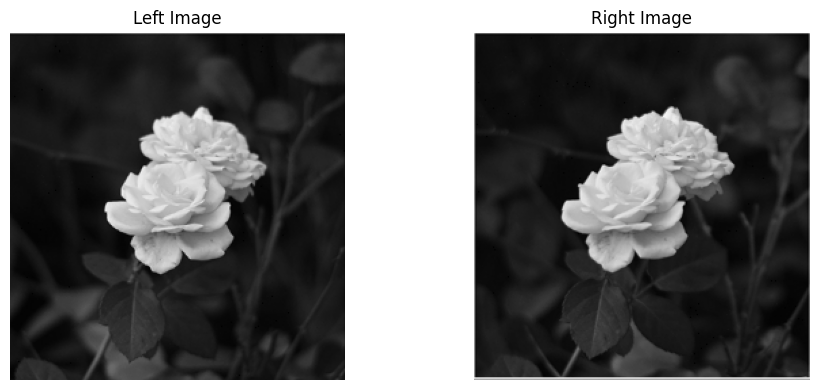

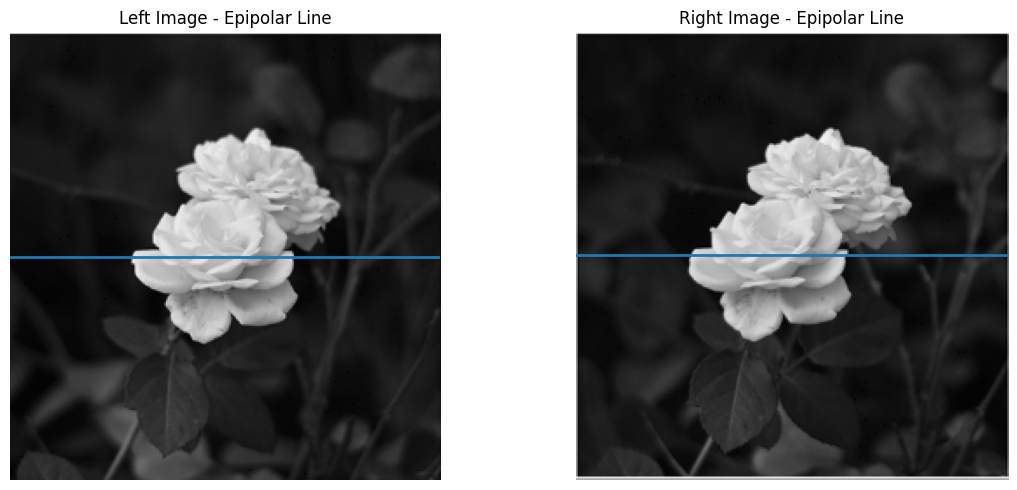

Selected epipolar row: 128


In [ ]:
#task 1
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_left = cv2.imread('/content/CV.png', 0)
img_right = cv2.imread('/content/cv2.png', 0)

# Check if images loaded successfully
if img_left is None or img_right is None:
    print("Error: Could not load image(s). Check file paths and formats.")
    raise FileNotFoundError("Stereo image(s) could not be loaded.")

# Check image dimensions
print("Left image shape:", img_left.shape)
print("Right image shape:", img_right.shape)

# Verify that both images have the same dimensions
if img_left.shape == img_right.shape:
    print("Both images have the same dimensions.")
else:
    print("The images have different dimensions.")

# Display the stereo images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_left, cmap='gray')
plt.title('Left Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_right, cmap='gray')
plt.title('Right Image')
plt.axis('off')

plt.tight_layout()
plt.show()

# Select the middle row
row = img_left.shape[0] // 2

# Display horizontal epipolar lines
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_left, cmap='gray')
plt.axhline(row, linewidth=2)
plt.title('Left Image - Epipolar Line')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_right, cmap='gray')
plt.axhline(row, linewidth=2)
plt.title('Right Image - Epipolar Line')
plt.axis('off')

plt.tight_layout()
plt.show()

print("Selected epipolar row:", row)

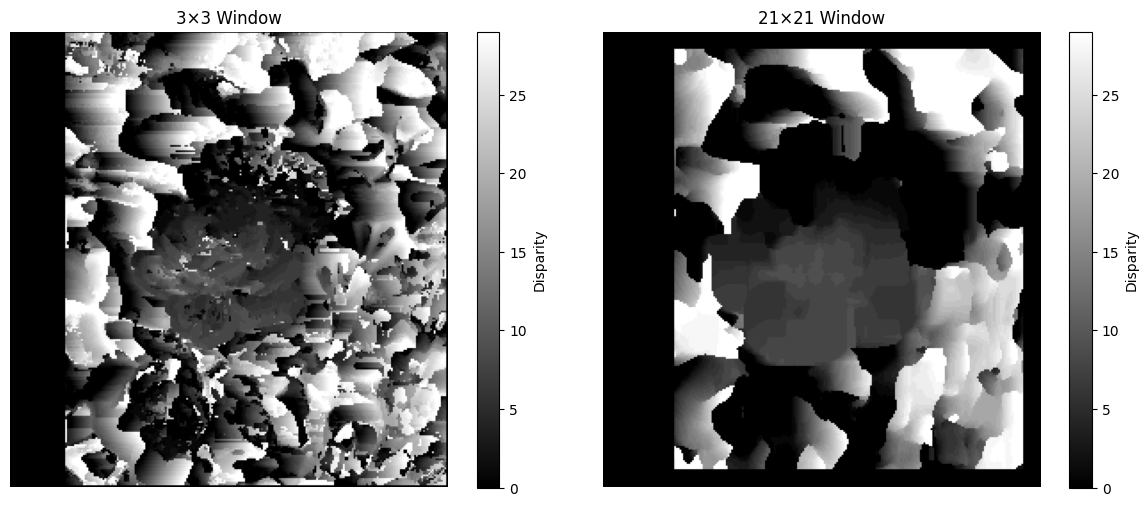

In [ ]:
#task 2
def compute_ssd_disparity(left_img, right_img, window_size, max_disparity=30):

    # Get image dimensions
    h, w = left_img.shape

    # Half of the window size
    half = window_size // 2

    # Create an empty disparity map
    disparity_map = np.zeros((h, w), dtype=np.float32)

    # Convert images to float for subtraction
    left_img = left_img.astype(np.float32)
    right_img = right_img.astype(np.float32)

    # Loop through valid image pixels
    for y in range(half, h - half):

        for x in range(half + max_disparity, w - half):

            # Extract the left image patch
            left_patch = left_img[
                y-half:y+half+1,
                x-half:x+half+1
            ]

            min_ssd = float('inf')
            best_disparity = 0

            # Search over possible disparities
            for disparity in range(max_disparity):

                x_right = x - disparity

                # Check image boundary
                if x_right - half < 0:
                    break

                # Extract the corresponding right image patch
                right_patch = right_img[
                    y-half:y+half+1,
                    x_right-half:x_right+half+1
                ]

                # Calculate SSD
                ssd = np.sum((left_patch - right_patch) ** 2)

                # Find the best match
                if ssd < min_ssd:
                    min_ssd = ssd
                    best_disparity = disparity

            # Store best disparity
            disparity_map[y, x] = best_disparity

    return disparity_map


# Compute disparity using the 3x3 window
disp_3 = compute_ssd_disparity(
    img_left,
    img_right,
    window_size=3,
    max_disparity=30
)

# Compute disparity using the 21x21 window
disp_21 = compute_ssd_disparity(
    img_left,
    img_right,
    window_size=21,
    max_disparity=30
)

# Display both disparity maps
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(disp_3, cmap='gray')
plt.colorbar(label='Disparity')
plt.title('3×3 Window')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(disp_21, cmap='gray')
plt.colorbar(label='Disparity')
plt.title('21×21 Window')
plt.axis('off')

plt.tight_layout()
plt.show()

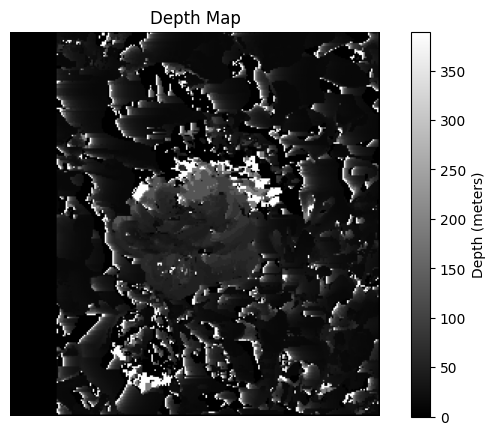

In [ ]:
#task 3
# Camera parameters from Lab 03.md
B = 0.54
f = 721.5

def compute_depth(disparity_map, baseline, focal_length):

    depth_map = np.zeros_like(
        disparity_map,
        dtype=np.float32
    )

    # Only calculate depth where disparity is positive
    valid = disparity_map > 0

    depth_map[valid] = (
        baseline * focal_length
    ) / disparity_map[valid]

    return depth_map


# Calculate depth using the 3x3 disparity map
depth_map = compute_depth(
    disp_3,
    B,
    f
)

# Display the depth map
plt.figure(figsize=(8, 5))

plt.imshow(depth_map, cmap='gray')
plt.colorbar(label='Depth (meters)')
plt.title('Depth Map')
plt.axis('off')

plt.show()

In [ ]:
#task 4

# Effect of Disparity

B = 0.54
f = 721.5

disparities = [5, 10, 20, 30]

print("Effect of Disparity")

for d in disparities:

    depth = (B * f) / d

    print(
        f"Disparity = {d:2d} pixels "
        f"-> Depth = {depth:.2f} meters"
    )

# Effect of Baseline

f = 721.5
d = 20

baselines = [0.30, 0.54, 1.00]

print("\nEffect of Baseline")

for B in baselines:

    depth = (B * f) / d

    print(
        f"Baseline = {B:.2f} m "
        f"-> Depth = {depth:.2f} m"
    )

# Effect of Focal Length

B = 0.54
d = 20

focal_lengths = [500, 721.5, 1000]

print("\nEffect of Focal Length")

for f in focal_lengths:

    depth = (B * f) / d

    print(
        f"Focal Length = {f:.1f} pixels "
        f"-> Depth = {depth:.2f} m"
    )

Effect of Disparity
Disparity =  5 pixels -> Depth = 77.92 meters
Disparity = 10 pixels -> Depth = 38.96 meters
Disparity = 20 pixels -> Depth = 19.48 meters
Disparity = 30 pixels -> Depth = 12.99 meters

Effect of Baseline
Baseline = 0.30 m -> Depth = 10.82 m
Baseline = 0.54 m -> Depth = 19.48 m
Baseline = 1.00 m -> Depth = 36.08 m

Effect of Focal Length
Focal Length = 500.0 pixels -> Depth = 13.50 m
Focal Length = 721.5 pixels -> Depth = 19.48 m
Focal Length = 1000.0 pixels -> Depth = 27.00 m
